# Task 4: Dataset Exploration — Oxford-102 Flowers

**Goal:** Load and examine the Oxford-102 Flowers dataset. Analyze dataset statistics
(number of classes, description length, image resolution) and visualize text
descriptions paired with images.

This notebook runs on **Google Colab**. GPU isn't required for this task since
we're only doing data exploration — CPU runtime is fine.

**Output of this task feeds directly into:**
- Task 3 (text preprocessing / embeddings) — uses the text descriptions built here
- Task 2 & 5 (GAN training) — uses the images + labels loaded here
- Task 6 (full pipeline) — uses everything from this notebook

**Note on captions:** The original research captions for this dataset (10
hand-written sentences per image) were released as Torch `.t7` files on
mirrors that move around and regularly go offline. Instead of depending on a
fragile third-party copy, this notebook builds captions from the 102 official
flower category names (e.g. "pink primrose", "hard-leaved pocket orchid") —
this is stable, always available, and is exactly the kind of category-label
conditioning Task 2 (cGAN) asks for anyway.


In [1]:
!pip install -q scipy pillow matplotlib pandas


In [2]:
import os
import scipy.io
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import urllib.request
import tarfile

DATA_DIR = "flowers_data"
os.makedirs(DATA_DIR, exist_ok=True)


## 1. Download the dataset (images + labels)

Official University of Oxford VGG source.


In [3]:
IMAGES_URL = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz"
LABELS_URL = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/imagelabels.mat"

images_tgz = os.path.join(DATA_DIR, "102flowers.tgz")
labels_path = os.path.join(DATA_DIR, "imagelabels.mat")

if not os.path.exists(images_tgz):
    urllib.request.urlretrieve(IMAGES_URL, images_tgz)
if not os.path.exists(labels_path):
    urllib.request.urlretrieve(LABELS_URL, labels_path)

jpg_dir = os.path.join(DATA_DIR, "jpg")
if not os.path.exists(jpg_dir):
    with tarfile.open(images_tgz) as tar:
        tar.extractall(DATA_DIR)

print("Images and labels ready.")


/tmp/ipykernel_4908/1410439450.py:15: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(DATA_DIR)


Images and labels ready.


## 2. Class names and caption generation

These are the 102 official category names from the Oxford Flowers dataset
paper (Nilsback & Zisserman, 2008), in label-id order (1-indexed to match
`imagelabels.mat`). We use these to build a simple caption per image, and
also as the category label for cGAN conditioning in Task 2.


In [4]:
FLOWER_CLASSES = [
    "pink primrose", "hard-leaved pocket orchid", "canterbury bells", "sweet pea",
    "english marigold", "tiger lily", "moon orchid", "bird of paradise", "monkshood",
    "globe thistle", "snapdragon", "colt's foot", "king protea", "spear thistle",
    "yellow iris", "globe flower", "purple coneflower", "peruvian lily", "balloon flower",
    "giant white arum lily", "fire lily", "pincushion flower", "fritillary", "red ginger",
    "grape hyacinth", "corn poppy", "prince of wales feathers", "stemless gentian",
    "artichoke", "sweet william", "carnation", "garden phlox", "love in the mist",
    "mexican aster", "alpine sea holly", "ruby-lipped cattleya", "cape flower",
    "great masterwort", "siam tulip", "lenten rose", "barbeton daisy", "daffodil",
    "sword lily", "poinsettia", "bolero deep blue", "wallflower", "marigold", "buttercup",
    "oxeye daisy", "common dandelion", "petunia", "wild pansy", "primula", "sunflower",
    "pelargonium", "bishop of llandaff", "gaura", "geranium", "orange dahlia",
    "pink-yellow dahlia", "cautleya spicata", "japanese anemone", "black-eyed susan",
    "silverbush", "californian poppy", "osteospermum", "spring crocus", "bearded iris",
    "windflower", "tree poppy", "gazania", "azalea", "water lily", "rose", "thorn apple",
    "morning glory", "passion flower", "lotus", "toad lily", "anthurium", "frangipani",
    "clematis", "hibiscus", "columbine", "desert-rose", "tree mallow", "magnolia",
    "cyclamen", "watercress", "canna lily", "hippeastrum", "bee balm", "air plant",
    "foxglove", "bougainvillea", "camellia", "mallow", "mexican petunia", "bromelia",
    "blanket flower", "trumpet creeper", "blackberry lily"
]
print(f"Number of class names: {len(FLOWER_CLASSES)}")  # should be 102


Number of class names: 102


In [5]:
def make_caption(class_name):
    """Create a simple natural-language caption from the flower class name."""
    # Avoid captions such as "passion flower flower" or "wallflower flower".
    if "flower" in class_name.lower():
        return f"a photo of a {class_name}"
    return f"a photo of a {class_name} flower"

# Quick sanity check
for i in [0, 1, 50, 101]:
    print(f'Label {i+1}: {FLOWER_CLASSES[i]} -> "{make_caption(FLOWER_CLASSES[i])}"')


Label 1: pink primrose -> "a photo of a pink primrose flower"
Label 2: hard-leaved pocket orchid -> "a photo of a hard-leaved pocket orchid flower"
Label 51: petunia -> "a photo of a petunia flower"
Label 102: blackberry lily -> "a photo of a blackberry lily flower"


## 3. Load labels and build a working dataframe


In [6]:
labels_mat = scipy.io.loadmat(labels_path)
labels = labels_mat["labels"][0]  # 1-indexed class ids, length = number of images

image_files = sorted(os.listdir(jpg_dir))
print(f"Number of images found: {len(image_files)}")
print(f"Number of labels found: {len(labels)}")

df = pd.DataFrame({
    "filename": image_files,
    "label": labels[:len(image_files)]
})
df["class_name"] = df["label"].apply(lambda l: FLOWER_CLASSES[l - 1])
df["caption"] = df["class_name"].apply(make_caption)
df.head()


Number of images found: 8189
Number of labels found: 8189


,filename,label,class_name,caption
0,image_00001.jpg,77,passion flower,a photo of a passion flower
1,image_00002.jpg,77,passion flower,a photo of a passion flower
2,image_00003.jpg,77,passion flower,a photo of a passion flower
3,image_00004.jpg,77,passion flower,a photo of a passion flower
4,image_00005.jpg,77,passion flower,a photo of a passion flower


## 4. Dataset statistics

- Number of classes
- Images per class (distribution)
- Image resolution distribution
- Caption length distribution


Number of classes: 102
Total images: 8189
Min images per class: 40
Max images per class: 258
Mean images per class: 80.3


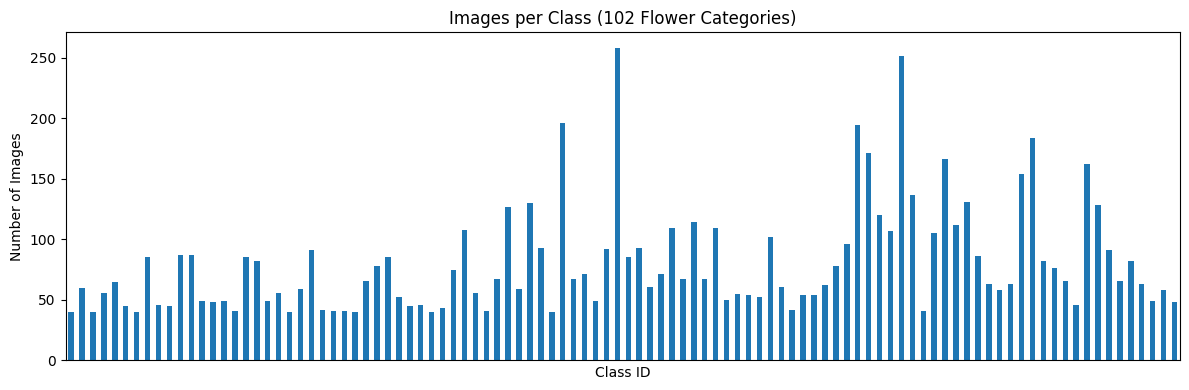

In [7]:
num_classes = df["label"].nunique()
print(f"Number of classes: {num_classes}")
print(f"Total images: {len(df)}")

class_counts = df["label"].value_counts().sort_index()
print(f"Min images per class: {class_counts.min()}")
print(f"Max images per class: {class_counts.max()}")
print(f"Mean images per class: {class_counts.mean():.1f}")

plt.figure(figsize=(12, 4))
class_counts.plot(kind="bar")
plt.title("Images per Class (102 Flower Categories)")
plt.xlabel("Class ID")
plt.ylabel("Number of Images")
plt.xticks([])
plt.tight_layout()
plt.show()


            width      height
count  300.000000  300.000000
mean   620.493333  538.673333
std     95.616797   79.208965
min    500.000000  500.000000
25%    500.000000  500.000000
50%    666.000000  500.000000
75%    676.250000  523.000000
max    820.000000  943.000000


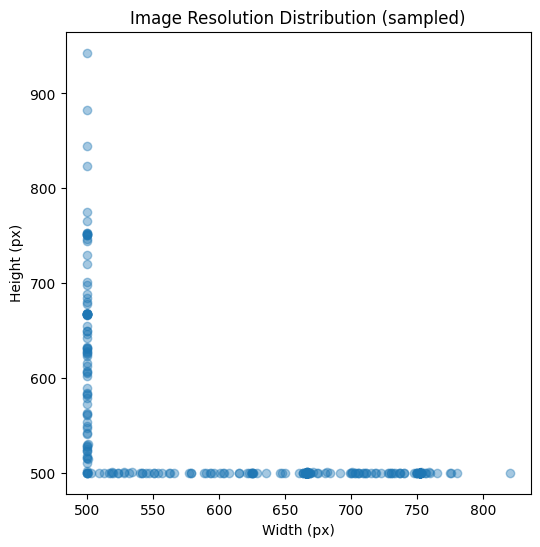

In [8]:
# Image resolution stats - sample a subset for speed
sample_files = df["filename"].sample(n=min(300, len(df)), random_state=42)
resolutions = []
for fname in sample_files:
    with Image.open(os.path.join(jpg_dir, fname)) as img:
        resolutions.append(img.size)  # (width, height)

res_df = pd.DataFrame(resolutions, columns=["width", "height"])
print(res_df.describe())

plt.figure(figsize=(6, 6))
plt.scatter(res_df["width"], res_df["height"], alpha=0.4)
plt.title("Image Resolution Distribution (sampled)")
plt.xlabel("Width (px)")
plt.ylabel("Height (px)")
plt.show()


count    8189.000000
mean        6.495054
std         0.715780
min         5.000000
25%         6.000000
50%         6.000000
75%         7.000000
max         9.000000
Name: caption_length, dtype: float64


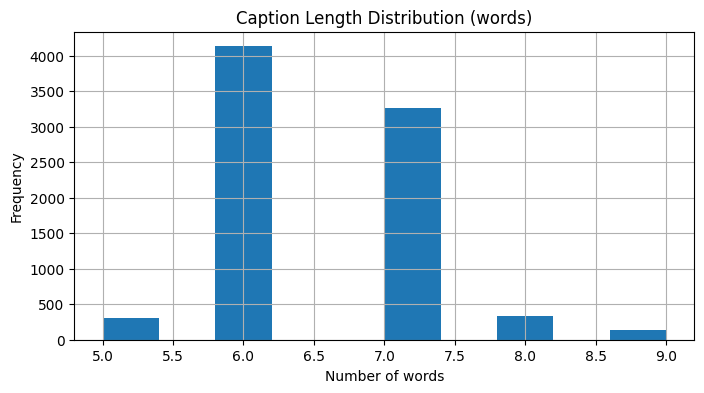

In [9]:
# Caption length stats
df["caption_length"] = df["caption"].apply(lambda c: len(c.split()))
print(df["caption_length"].describe())

plt.figure(figsize=(8, 4))
df["caption_length"].hist(bins=10)
plt.title("Caption Length Distribution (words)")
plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.show()


## 5. Visualize: images paired with their text descriptions

This is the core deliverable for Task 4 — showing that image and text data
are correctly linked, which is the foundation for Tasks 3, 2, 5, and 6.


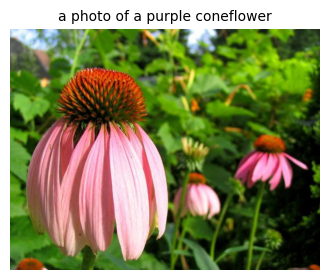

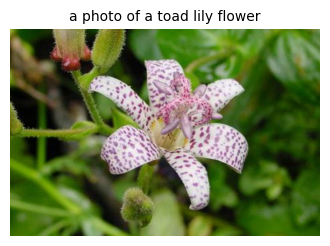

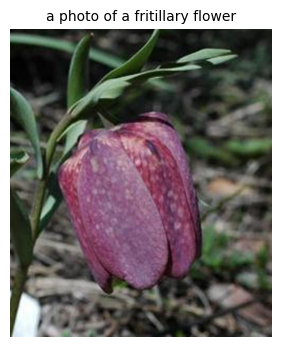

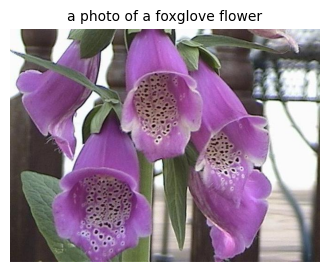

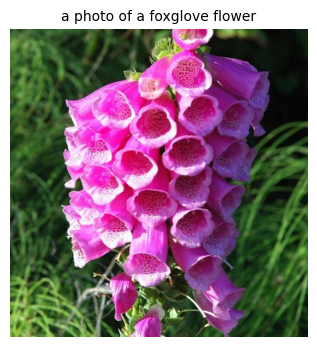

In [10]:
def show_image_with_caption(row):
    img_path = os.path.join(jpg_dir, row["filename"])
    with Image.open(img_path) as img:
        plt.figure(figsize=(4, 4))
        plt.imshow(img)
        plt.axis("off")
        plt.title(row["caption"], fontsize=10)
        plt.show()

sample_rows = df.sample(n=5, random_state=1)
for _, row in sample_rows.iterrows():
    show_image_with_caption(row)


## 6. Save the processed dataframe

We'll reuse this directly in Task 3 (text preprocessing) so we don't have to
redo the download/labeling step.


In [11]:
df.to_csv("flowers_dataset_processed.csv", index=False)
print("Saved flowers_dataset_processed.csv")
df.head()


Saved flowers_dataset_processed.csv


,filename,label,class_name,caption,caption_length
0,image_00001.jpg,77,passion flower,a photo of a passion flower,6
1,image_00002.jpg,77,passion flower,a photo of a passion flower,6
2,image_00003.jpg,77,passion flower,a photo of a passion flower,6
3,image_00004.jpg,77,passion flower,a photo of a passion flower,6
4,image_00005.jpg,77,passion flower,a photo of a passion flower,6


## 7. Summary

The Oxford-102 Flowers dataset was successfully loaded and explored. The analysis included class distribution, image-resolution variability, caption lengths, and visualization of images together with their generated textual descriptions.

The following cell automatically reports the final dataset statistics after execution.


In [12]:
print("===== TASK 4 SUMMARY =====")
print(f"Total images: {len(df)}")
print(f"Number of classes: {df['label'].nunique()}")

class_counts = df["label"].value_counts()
print(f"Images per class range: {class_counts.min()} to {class_counts.max()}")

print(
    f"Sampled image resolution range: "
    f"{res_df['width'].min()}x{res_df['height'].min()} to "
    f"{res_df['width'].max()}x{res_df['height'].max()} pixels"
)

print(
    f"Caption length range: "
    f"{df['caption_length'].min()} to {df['caption_length'].max()} words"
)

print(
    "\nObservation: The dataset contains 102 flower categories with an "
    "unequal number of images across classes. Images also vary in resolution. "
    "Template-based captions provide simple textual descriptions for each "
    "flower category and will be used for text encoding in the next task."
)


===== TASK 4 SUMMARY =====
Total images: 8189
Number of classes: 102
Images per class range: 40 to 258
Sampled image resolution range: 500x500 to 820x943 pixels
Caption length range: 5 to 9 words

Observation: The dataset contains 102 flower categories with an unequal number of images across classes. Images also vary in resolution. Template-based captions provide simple textual descriptions for each flower category and will be used for text encoding in the next task.
